<a href="https://colab.research.google.com/github/MilaniS-sudo/ASR700-Robotics-Assignment/blob/main/component_a/question2/motion_planning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DIJKSTRA
Path length (steps): 18
Nodes explored: 86
Average execution time (ms): 0.2246

A*
Path length (steps): 18
Nodes explored: 84
Average execution time (ms): 0.226


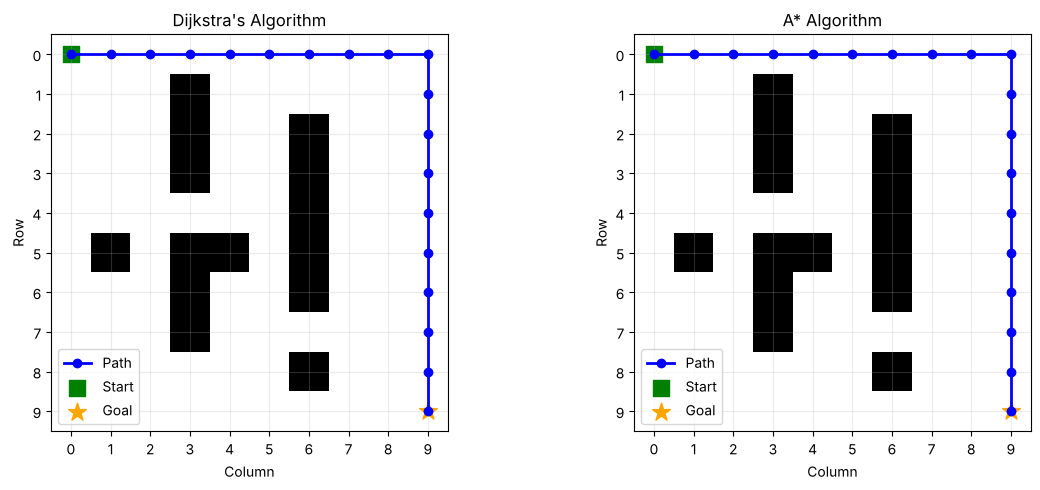

In [1]:

import heapq
import time
import numpy as np
import matplotlib.pyplot as plt


# 0 = free space, 1 = obstacle
grid = np.zeros((10, 10), dtype=int)

# Add obstacles to create a navigation environment.
grid[1:8, 3] = 1
grid[4, 3] = 0

grid[2:9, 6] = 1
grid[7, 6] = 0

grid[5, 1:5] = 1
grid[5, 2] = 0

START = (0, 0)
GOAL = (9, 9)


def get_neighbours(position):
    """Return valid up, down, left and right neighbours."""
    row, col = position
    candidates = [
        (row - 1, col),
        (row + 1, col),
        (row, col - 1),
        (row, col + 1)
    ]

    valid = []

    for r, c in candidates:
        if (0 <= r < grid.shape[0]
                and 0 <= c < grid.shape[1]
                and grid[r, c] == 0):
            valid.append((r, c))

    return valid


def heuristic(position, goal):
    """Manhattan distance for four-direction movement."""
    return abs(position[0] - goal[0]) + abs(position[1] - goal[1])


def search(start, goal, use_astar=False):
    """Run Dijkstra (False) or A* (True)."""
    frontier = []
    initial_h = heuristic(start, goal) if use_astar else 0

    heapq.heappush(frontier, (initial_h, 0, start))

    distances = {start: 0}
    parents = {}
    explored = set()

    while frontier:
        priority, cost, current = heapq.heappop(frontier)

        # Ignore outdated entries in the priority queue.
        if cost != distances.get(current):
            continue

        if current in explored:
            continue

        explored.add(current)

        if current == goal:
            break

        for neighbour in get_neighbours(current):
            new_cost = cost + 1

            if new_cost < distances.get(neighbour, float("inf")):
                distances[neighbour] = new_cost
                parents[neighbour] = current

                h = heuristic(neighbour, goal) if use_astar else 0
                heapq.heappush(
                    frontier,
                    (new_cost + h, new_cost, neighbour)
                )

    if goal not in distances:
        return [], len(explored), float("inf")

    # Reconstruct the path from goal back to start.
    path = []
    current = goal

    while current != start:
        path.append(current)
        current = parents[current]

    path.append(start)
    path.reverse()

    return path, len(explored), distances[goal]


# Run each algorithm once for results, then time over 1000 runs.
def average_time(use_astar, runs=1000):
    """Average execution time over many runs (single runs are too noisy)."""
    start_time = time.perf_counter()
    for _ in range(runs):
        search(START, GOAL, use_astar=use_astar)
    return (time.perf_counter() - start_time) / runs


dijkstra_path, dijkstra_nodes, dijkstra_cost = search(START, GOAL, use_astar=False)
astar_path, astar_nodes, astar_cost = search(START, GOAL, use_astar=True)
dijkstra_time = average_time(False)
astar_time = average_time(True)


# Display results.
print("DIJKSTRA")
print("Path length (steps):", dijkstra_cost)
print("Nodes explored:", dijkstra_nodes)
print("Average execution time (ms):", round(dijkstra_time * 1000, 4))

print("\nA*")
print("Path length (steps):", astar_cost)
print("Nodes explored:", astar_nodes)
print("Average execution time (ms):", round(astar_time * 1000, 4))


# Visualise both paths.


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

results = [
    (axes[0], dijkstra_path, "Dijkstra's Algorithm"),
    (axes[1], astar_path, "A* Algorithm")
]

for ax, path, title in results:
    ax.imshow(grid, cmap="Greys", origin="upper", vmin=0, vmax=1)

    if path:
        rows = [point[0] for point in path]
        cols = [point[1] for point in path]
        ax.plot(cols, rows, marker="o", linewidth=2,
                color="blue", label="Path")

    ax.scatter(START[1], START[0], marker="s",
               s=120, color="green", label="Start")

    ax.scatter(GOAL[1], GOAL[0], marker="*",
               s=180, color="orange", label="Goal")

    ax.set_title(title)
    ax.set_xticks(range(grid.shape[1]))
    ax.set_yticks(range(grid.shape[0]))
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.grid(True, alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()




Comparison of Dijkstra’s Algorithm and A*

Dijkstra’s algorithm and A* were tested on the same 10 × 10 occupancy grid, where 0 represents free space and 1 represents an obstacle. Both algorithms found a path of 18 steps.

Dijkstra explored 86 nodes and A* explored 84 nodes. Execution time was averaged over 1,000 runs, because a single run on a grid this small is dominated by timing noise. The average times were almost identical (about 0.22 ms each), with A* marginally slower: its two fewer expansions did not offset the extra cost of computing the heuristic at every node.

Both algorithms found paths of equal length. A* uses the Manhattan distance heuristic to guide its search toward the goal, whereas Dijkstra explores according to accumulated path cost. On this small, maze-like grid the heuristic gives A* little guidance, because walls force the path away from the straight line to the goal. A*'s advantage is expected to grow on larger, more open maps.

Limitation: These tests use a simulated occupancy grid in Python. The algorithms still need to be integrated and tested in Webots for the robot simulation.

In [2]:
def validate_path(path, grid):
    if not path:
        return False

    for row, col in path:
        if not (0 <= row < grid.shape[0]
                and 0 <= col < grid.shape[1]):
            return False

        if grid[row, col] == 1:
            return False

    for i in range(1, len(path)):
        r1, c1 = path[i - 1]
        r2, c2 = path[i]

        # Each move must be one step up, down, left or right
        if abs(r1 - r2) + abs(c1 - c2) != 1:
            return False

    return True


print("Dijkstra path valid:",
      validate_path(dijkstra_path, grid))

print("A* path valid:",
      validate_path(astar_path, grid))

Dijkstra path valid: True
A* path valid: True


Occupancy Grid Representation

The environment is represented using a 10 × 10 occupancy grid. Each cell is assigned a value: 0 represents free space, while 1 represents an obstacle. The robot starts at position (0, 0) and must reach the goal at position (9, 9).

The motion-planning algorithms consider movement in four directions: up, down, left and right. Cells outside the grid and cells containing obstacles are excluded from valid movements. This representation allows Dijkstra’s algorithm and A* to search for a valid route through the environment.

A* uses the Manhattan-distance heuristic to estimate the remaining distance to the goal. Because movement is restricted to four directions and each move costs one step, this heuristic is appropriate for guiding the search.